## Practical 10 - Visulaization

### `Problem`

You are using the iris dataset and plotting the following with the help of seaborn library:
* Scatter Plots
* Density Plots
* Violin Plots
* Heatmaps
* Joint Plots
* Pair plots
  
      You need to write your analysis after each plot. During Heatmaps your analysis should be in context of correlation. 

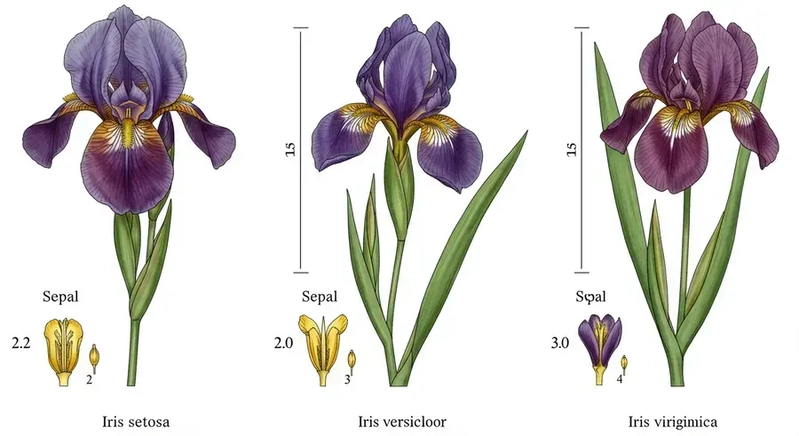

The Iris dataset is a famous machine-learning dataset containing measurements of three of Iris flowers:
* Setosa
* Versicolor
* Virginica

      It contains 150 observations and five columns:
  
| Column | Description |
| --- | --- |
| sepal_length | Length of the sepal |
| sepal_width | Width of the sepal |
| petal_length | Length of the petal |
| petal_width | Width of the petal |
| species | Type of Iris flower |
   
    The first four columns contain numerical measurements, and the last column identifies the flower species.



In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

%matplotlib inline

sns.set_theme(style = 'whitegrid')

print("All libraries imported successfully!")

print("\nLibrary Versions:")
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", plt.matplotlib.__version__)
print("Seaborn:", sns.__version__)
print("Scikit-learn Version:", sklearn.__version__)

All libraries imported successfully!

Library Versions:
Pandas: 3.0.5
NumPy: 2.5.2
Matplotlib: 3.11.1
Seaborn: 0.13.2
Scikit-learn Version: 1.9.1


#### Step 1: Load the Iris dataset

In [2]:
from sklearn.datasets import load_iris

# load Iris dataset
iris = load_iris()


print("Iris dataset loaded successfully!")

Iris dataset loaded successfully!


#### Step 2: Convert it into a Pandas DataFrame

In [3]:
#Create DataFrame
df = pd.DataFrame(iris.data, columns = iris.feature_names)

#Add species columnn
df['species'] = pd.Categorical.from_codes(iris.target, iris.target_names)

print("DataFrame created successfully!")

DataFrame created successfully!


#### Step 3: Display the dataset

In [4]:
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


#### Step 4: Verify the dataset

In [5]:
#Dataset dimensions
df.shape

(150, 5)

In [6]:
#Column information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype   
---  ------             --------------  -----   
 0   sepal length (cm)  150 non-null    float64 
 1   sepal width (cm)   150 non-null    float64 
 2   petal length (cm)  150 non-null    float64 
 3   petal width (cm)   150 non-null    float64 
 4   species            150 non-null    category
dtypes: category(1), float64(4)
memory usage: 5.0 KB


In [7]:
#Species distribution
df['species'].value_counts()

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

### `Scatter Plot`
    A Scatter Plot is a data visualization technique used to show the relationship between two numerical variables.
    It represents individual observations as points(dots) on a two-dimensional graph.
    Each point represents one observation or record in the dataset.

#### Why do we use a Scatter Plot?
* Identify relationship between two numerical variables.
* Understand whether a relationship is positive or negative
* Identify clusters or groups in data
* Detect unusual observations(outliers)
* Observe patterns and trends

For Scatter Plot, we'll select:
|Component|Variable|
|---|---|
|X-axis|petal_length|
|Y-axis|petal_width|
|colour(hue)|species|

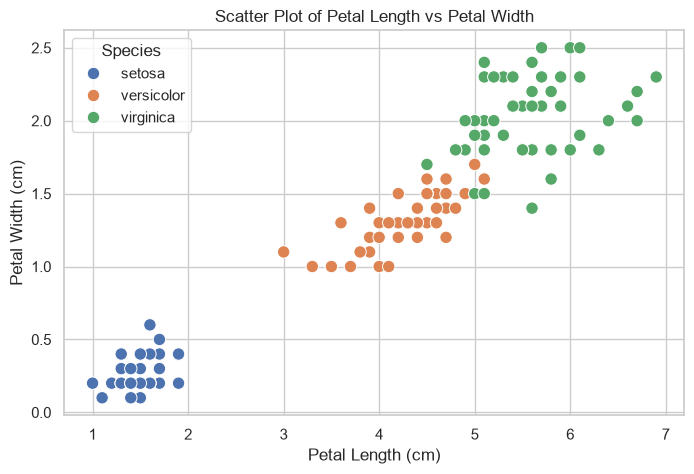

In [8]:
# Graph 1: Scatter Plot

plt.figure(figsize = (8,5))

sns.scatterplot(
    data = df,
    x = 'petal length (cm)',
    y = 'petal width (cm)',
    hue = 'species',
    s = 80
)

plt.title('Scatter Plot of Petal Length vs Petal Width')
plt.xlabel('Petal Length (cm)')
plt.ylabel('Petal Width (cm)')

plt.legend(title = 'Species')
plt.show()

#### `Analysis of Scatter Plot`
         
    1. The Scatter Plot illustrates the relationship between petal length and petal width across the three species of Iris flowers:
       Setosa, Versicolor, Virginica
    
    2. It shows a strong positive relationship between petal length and petal width, indicating that flowers with longer petals 
       generally tend to have wider petals
    
    3. Setosa flowers form a clearly separated cluster with smaller petal measurements.
       Versicolor and Virginica generally have larger petal measurements, although some overlap is observed between these two species.

    Overall, the scatter plot demonstrates that petal length and petal width are useful features for distinguishing different Iris species.

### `Density Plot`
    A Density Plot is a graphical representation used to understand the distribution of numerical data.
    It shows how values are spread across a range and where observations are more concentrated
    
    A Density Plot uses a statistical technique called Kernel Density Estimation (KDE) to create a smooth curve representing the distribution of data 

#### Why do we use a Density Plot?
* Understand the distribution of numerical variables
* Identify where observations are concentrated
* Compare distributions between different categories
* Identify whether a distribution is symmetric or skewed
* Observe peaks and multiple concentration regions

For Density Plot we'll use:
|Component|Variable|
|---|---|
|X-axis|petal_length|
|Y-axis|Density|
|colour(hue)|species|

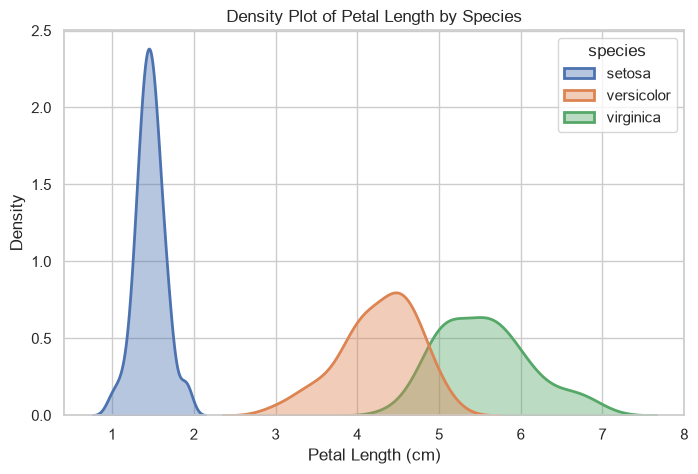

In [9]:
# Graph 2: Density Plot

plt.figure(figsize = (8,5))

sns.kdeplot(
    data = df,
    x = 'petal length (cm)',
    hue = 'species',
    fill = True,
    common_norm = False,
    alpha = 0.4,
    linewidth = 2
)

plt.title('Density Plot of Petal Length by Species')
plt.xlabel('Petal Length (cm)')
plt.ylabel('Density')

plt.show()

#### `Analysis of Density Plot`
    
    1. The Density Plot illustrates the distribution of petal length among the three Iris flower species: Setosa, Versicolor, and Virginica

    2. The Setosa species shows a distribution concentrated at shorter petal lengths,
       whereas Versicolor has an intermediate distribution. Virginica generally exhibits a distribution towards longer petal lengths.

    3. The density curves indicate that the three species have different petal length deistributions,
       with Setosa being clearly separated from the other two species. Some overlap can be observed between Versicolor and Verginica

    Overall, the density plot demonstrates that petal length is an important feature for distinguishing different Iris species

### `Violin Plot`

    A Violin Plot is a statistical visualization used to understand the distribution and spread of numerical data across different categories 

    It combines:
    
         * Box Plot: Shows median, quartiles and potential outliers
         
         * Density Plot(KDE): Shows where observations are concentrated
    
    Its shapes resembles a violin, which is where it gets its name

#### Why do we use a violin plot?
* Compare distributions across different categories
* Understand data spread and variability
* Identify median values
* Observe concentration and distribution patterns
* Detect potential outliers and unusual distributions

For Violin Plot we'll use:
|Component|Variable|
|---|---|
|X-axis|species|
|Y-axis|petal_length|

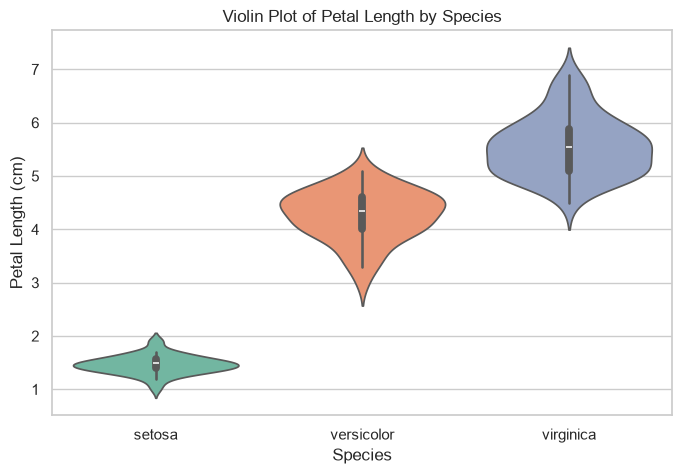

In [10]:
# Graph 3: Violin Plot 

plt.figure(figsize = (8,5))

sns.violinplot(
    data = df,
    x = 'species',
    y = 'petal length (cm)',
    hue = 'species',
    inner = 'box',
    palette = 'Set2',
    dodge = False,
    legend = False
)

plt.title('Violin Plot of Petal Length by Species')
plt.xlabel('Species')
plt.ylabel('Petal Length (cm)')

plt.show()

#### `Analysis of Violin Plot`

    1. The Violin Plot represents the distribution of petal length across the three Iris flower species: Setosa, Versicolor, and Virginica

    2. Setosa exhibits relatively shorter petal lengths with a concentrated distribution.
       Versicolor shows intermediate petal lengths, whereas Virginica generally has longer petal lengths.

    3. The inner box plots indicate the median and quartile distribution of each species. 
       The width of the violin shapes illustrates the density and concentration of observations at different petal lengths

    4. The plot also shows that Setosa is clearly distinguishable from the other two species, 
       while some overlap exists between Versicolor and Virginica

    Overall, the violin plot provides a useful comparison of the distribution, central tendency, and variability of petal length among the three species

### `Heatmap`

    A Heatmap is a graphical representation of numerical data in which different colours represent different values.

    It converts numercial data into a colour-coded visual representation, making it easier to identify patterns, relationships and variations

#### Why do we use a Heatmap?
* Identify relationships: Understand how two numerical values are related
* Find correlation: Identify positive and negative relationships
* Identify patterns: Recognize patterns through colour differences
* Compare variables: Compare the relationships between multiple numerical simultaneously
* Data analysis: Identify highly correlated features, which can be useful in machine learning and feature selection

For Heatmap we'll use:
* Sepal Length
* Sepal Width
* Petal Length
* Petal Width

In [11]:
# Calculate the Correlation Matrix

corr_matrix = df[
    ['sepal length (cm)',
     'sepal width (cm)',
     'petal length (cm)',
     'petal width (cm)']
].corr()

print(corr_matrix)

                   sepal length (cm)  sepal width (cm)  petal length (cm)  \
sepal length (cm)           1.000000         -0.117570           0.871754   
sepal width (cm)           -0.117570          1.000000          -0.428440   
petal length (cm)           0.871754         -0.428440           1.000000   
petal width (cm)            0.817941         -0.366126           0.962865   

                   petal width (cm)  
sepal length (cm)          0.817941  
sepal width (cm)          -0.366126  
petal length (cm)          0.962865  
petal width (cm)           1.000000  


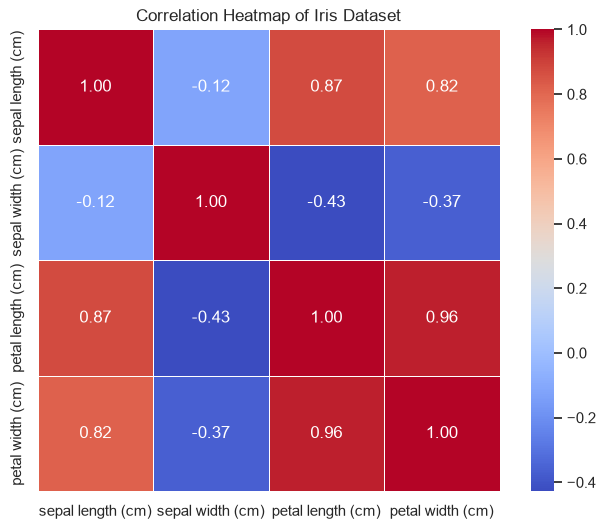

In [12]:
# Graph 4: Heatmap

plt.figure(figsize = (8,6))

sns.heatmap(
    corr_matrix,
    annot = True,
    cmap = 'coolwarm',
    fmt = '.2f',
    linewidths = 0.5,
    square = True
)

plt.title('Correlation Heatmap of Iris Dataset')

plt.show()

#### `Analysis of Heatmap (Correlation Analysis)`

    The Correlation Heatmap represents the relationship between the four numerical features of the Iris dataset: 
    sepal length, sepal width, petal length, petal width

    The heatmap indicates a very strong positive correlation between petal length and petal width, with a correlation coefficient of approximately 0.96
    This suggests that flowers with longer petals generally tend to have wider petals

    Sepal length also shows strong positive correlations with petal length (0.87) and petal width (0.82).
    On the other hand, sepal width exhibits negative correlations with petal length (-0.43) and petal width (-0.37)

    The relationship between sepal length and sepal width is weakly negative (-0.12)

    Overall, the heatmap demonstrates that petal length and petal width have the strongest positive relationship among the four numerical features.
    It helps identify patterns and understand the relationships between different measurements in the Iris dataset

### Joint Plot

    A Joint Plot displays the relationship between two numerical variables in a single visualization

    It combines:

        * Scatter Plot (centre): Shows the relationship between two variables
        * Marginal Distribution (top): Shows the distribution of the X-axis variable
        * Marginal Distribution (right): Shows the distribution of the Y-axis variable

    It helps us understand both the relationship and the individual distributions of two variables together

#### Why do we use it?

* Understand the relationship between two numerical variables
* Identify positive or negative associations
* Observe how values are distributed
* Identify clusters and possible outliers
* Examine whether different groups form separate patterns 

For Joint Plot we'll select:
|Component|Variable|
|---|---|
|X-axis|petal_length|
|Y-axis|petal_width|
|Hue|species|

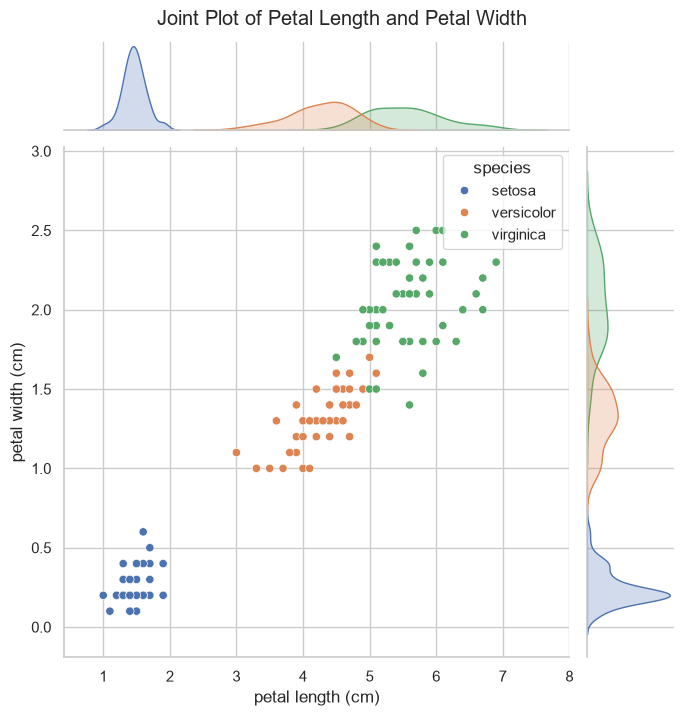

In [13]:
# Graph 5: Joint Plot 

sns.jointplot(
    data = df,
    x = 'petal length (cm)',
    y = 'petal width (cm)',
    hue = 'species',
    kind = 'scatter',
    height = 7
)

plt.suptitle('Joint Plot of Petal Length and Petal Width', y = '1.02')

plt.show()

#### `Analysis of Joint Plot`

    The Joint Plot illustrates the relationship between petal length and petal width in the Iris dataset

    The central scatter plot shows a positive relationship between these two variables, 
    indicating that flowers with longer petals generally tend to have wider petals

    The different colours represent the three Iris species and help identify their distribution patterns

    The marginal distributions at the top and right sides shows the individual distributions of petal length and petal width, respectively

    The plot also reveals clusters among the species, with Setosa appearing more clearly separated from Versicolor and Virginica 

    Overall, the Joint Plot provides a combined view of the relationship and distributions of two numerical variables

### Pair Plot

    A Pair Plot displays pairwise relationships between multiple numerical variables in a dataset

    It creates a grid of graphs:

        Diagonal: Shows the distribution of each individual numerical value

        Off-diagonal: Shows scatter plots comparing two different numerical variables

#### Why do we use a Pair Plot?

* Understand relationships among multiple numerical variables
* Identify positive and negative associations
* Compare distributions of individual variables
* Identify clusters and patterns among different species
* Discover which variable help distinguish different groups

For Pair Plot we'll select:

* sepal_length
* sepal_width
* petal_length
* petal_width

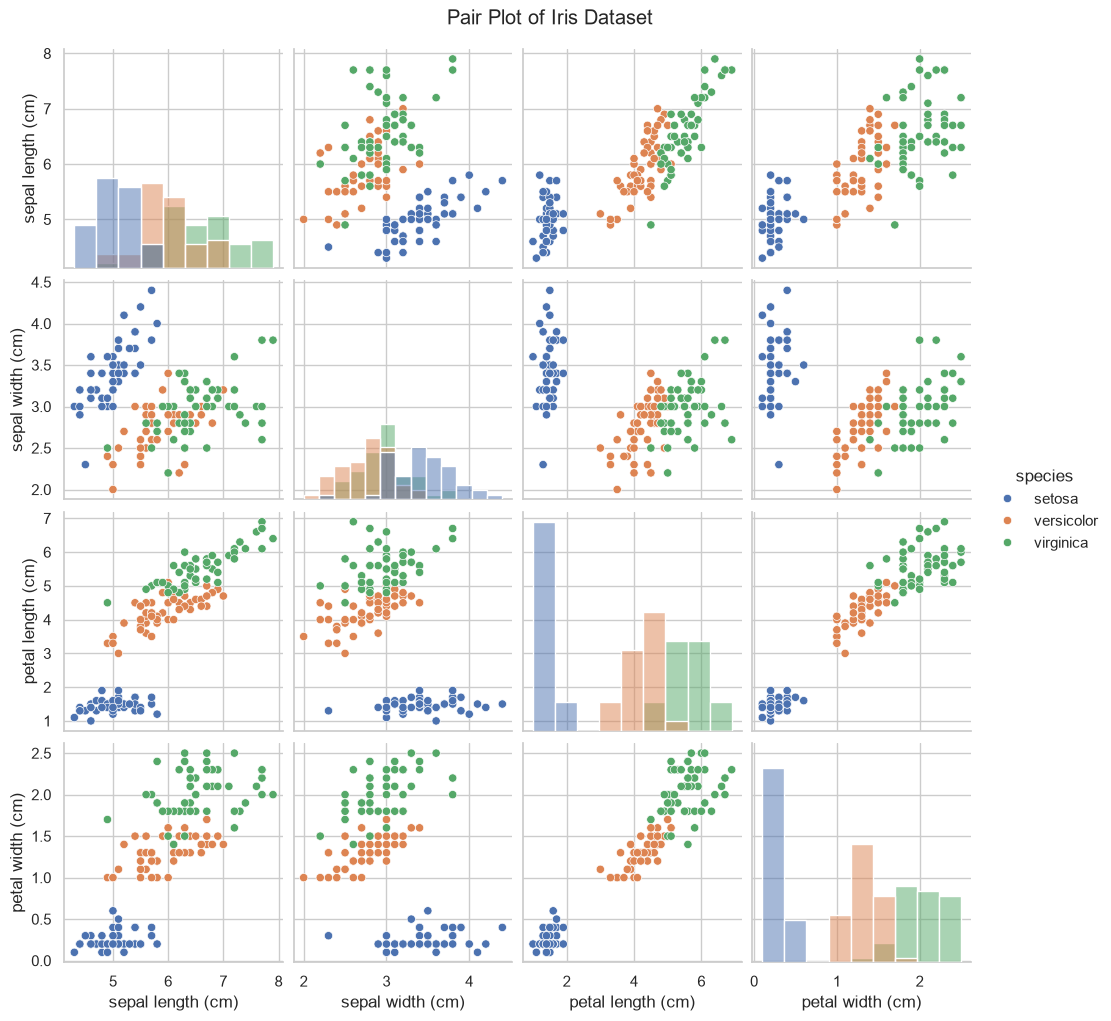

In [14]:
# Graph 6: Pair Plot 

sns.pairplot(
    data = df,
    vars = ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)'],
    hue = 'species',
    diag_kind = 'hist',
    height = 2.5
)

plt.suptitle('Pair Plot of Iris Dataset', y = 1.02)

plt.show()

#### `Analysis of Pair Plot`

    The Pair Plot provides a comprehensive visualization of pairwise relationships among the four numerical features of the Iris dataset:
    sepal length, sepal width, petal length and petal width

    The diagonal histograms represent the individual distributions of these features, while the scatter plots show relationships between pairs of variables
    Dfferent colours represent the three Iris species: Setosa, Versicolor, and Virginica

    The plot reveals a strong positive relationship between petal length and petal width. It also sohws that Setosa is clearly separated from the
    other two species based on petal measurements, whereas Versicolor and Virginica exhibit some overlap

    Overall, the pair plot helps identify relationships, distributions, clusters, and differences among the three species in a single visualization